# Bank Customer Churn: XGBoost + SHAP + Profit-Based Retention Targeting

**A guided, hands-on ML project.** Run it top to bottom first, then work through the **🧑‍💻 YOUR TURN** cells and see how the results change.

### The business problem
A bank loses customers ("churn"). It can send a **retention offer** (fee waiver, better rate, a call from a relationship manager), but every offer **costs money**. So the real question isn't just *"who will churn?"* but:

> **Which customers should we send an offer to so that we make the most money?**

### The plan
1. **EDA**: get to know the data
2. **Preprocessing pipeline**: turn raw columns into model-ready numbers
3. **Baseline**: logistic regression (simple, explainable)
4. **XGBoost**: a stronger model, with stratified cross-validation and early stopping
5. **Metrics**: ROC-AUC, PR-AUC, recall in the top 10%, calibration
6. **SHAP**: *why* the model predicts churn, overall and for one customer
7. **Profit-based targeting**: pick who to contact by expected profit, not accuracy
8. **Conclusions**

**Data:** [Churn Modelling](https://www.kaggle.com/datasets/shrutimechlearn/churn-modelling), 10,000 bank customers in France, Germany and Spain (a public dataset). `Exited = 1` means the customer left.

> 🧑‍💻 **There are 5 hands-on YOUR TURN tasks** (a groupby, feature selection, a hyperparameter experiment, explaining one customer, setting the business case). Each has a hint and a working default, so the notebook always runs end to end.
>
> 💡 **Tip:** a markdown cell explains each code cell. If a word is new, read the explanation first, then run the code.

> **TL;DR**
> 1. XGBoost reaches a test ROC-AUC of 0.871 vs 0.776 for logistic regression (5-fold CV 0.866 ± 0.010).
> 2. Calling the riskiest 10% of customers reaches 42% of all churners; SHAP's top drivers are number of products, age, activity and being in Germany.
> 3. Expected-value targeting earns $75,871 by contacting 715 of 2,000 customers, $46,168 more than contacting everyone (assumed $50 offer, 30% success rate).

In [1]:
import glob, os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve, precision_recall_curve, brier_score_loss
from sklearn.calibration import calibration_curve
import xgboost as xgb

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
SEED = 42
print("xgboost", xgb.__version__)

def find_file(name):
    for root in ["/kaggle/input", "../input", "data", "/workspace/kaggle/data"]:
        hits = glob.glob(os.path.join(root, "**", name), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(name)

raw = pd.read_csv(find_file("Churn_Modelling.csv"))
# Drop identifier columns: they say nothing about behaviour and shouldn't be used to model people
raw = raw.drop(columns=["RowNumber", "CustomerId", "Surname"])
print(raw.shape)
raw.head()

xgboost 3.4.1
(10000, 11)


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 1. EDA: get to know the data
First checks: are there missing values, how many customers churn, and which columns look related to churn?

In [2]:
print("Missing values per column:", int(raw.isna().sum().sum()))
churn_rate = raw["Exited"].mean()
print(f"Churn rate: {churn_rate:.1%}  ->  about 1 in {1/churn_rate:.0f} customers left")
raw.describe().T.round(2)

Missing values per column: 0
Churn rate: 20.4%  ->  about 1 in 5 customers left


,count,mean,std,min,25%,50%,75%,max
CreditScore,10000.0,650.53,96.65,350.00,584.00,652.00,718.00,850.00
Age,10000.0,38.92,10.49,18.00,32.00,37.00,44.00,92.00
Tenure,10000.0,5.01,2.89,0.00,3.00,5.00,7.00,10.00
Balance,10000.0,76485.89,62397.41,0.00,0.00,97198.54,127644.24,250898.09
NumOfProducts,10000.0,1.53,0.58,1.00,1.00,1.00,2.00,4.00
HasCrCard,10000.0,0.71,0.46,0.00,0.00,1.00,1.00,1.00
IsActiveMember,10000.0,0.52,0.50,0.00,0.00,1.00,1.00,1.00
EstimatedSalary,10000.0,100090.24,57510.49,11.58,51002.11,100193.92,149388.25,199992.48
Exited,10000.0,0.20,0.40,0.00,0.00,0.00,0.00,1.00


**Why the churn rate matters:** only about 20% of customers churn, so the classes are **imbalanced**. A lazy model that predicts "nobody churns" would be 80% *accurate* and completely useless. That's why this notebook doesn't judge models on accuracy. It uses ranking metrics (AUC) and money instead.

### 🧑‍💻 YOUR TURN #1: write your first groupby
**Task:** work out the churn rate **for each country** (`Geography`).
Because `Exited` is 0/1, its *mean* is the churn rate.

A working answer is already filled in. To practise, delete the line marked `<- answer` and write it yourself using the hint.
Then try a second one: churn rate by `NumOfProducts` or by `Gender`.

In [3]:
# HINT: df.groupby("<column to split by>")["<column to average>"].mean()
churn_by_country = raw.groupby("Geography")["Exited"].mean()   # <- answer (rewrite it yourself!)

# Extra: change "Geography" to "NumOfProducts" or "Gender" and run again
print(churn_by_country.sort_values(ascending=False).map("{:.1%}".format))

Geography
Germany    32.4%
Spain      16.7%
France     16.2%
Name: Exited, dtype: str


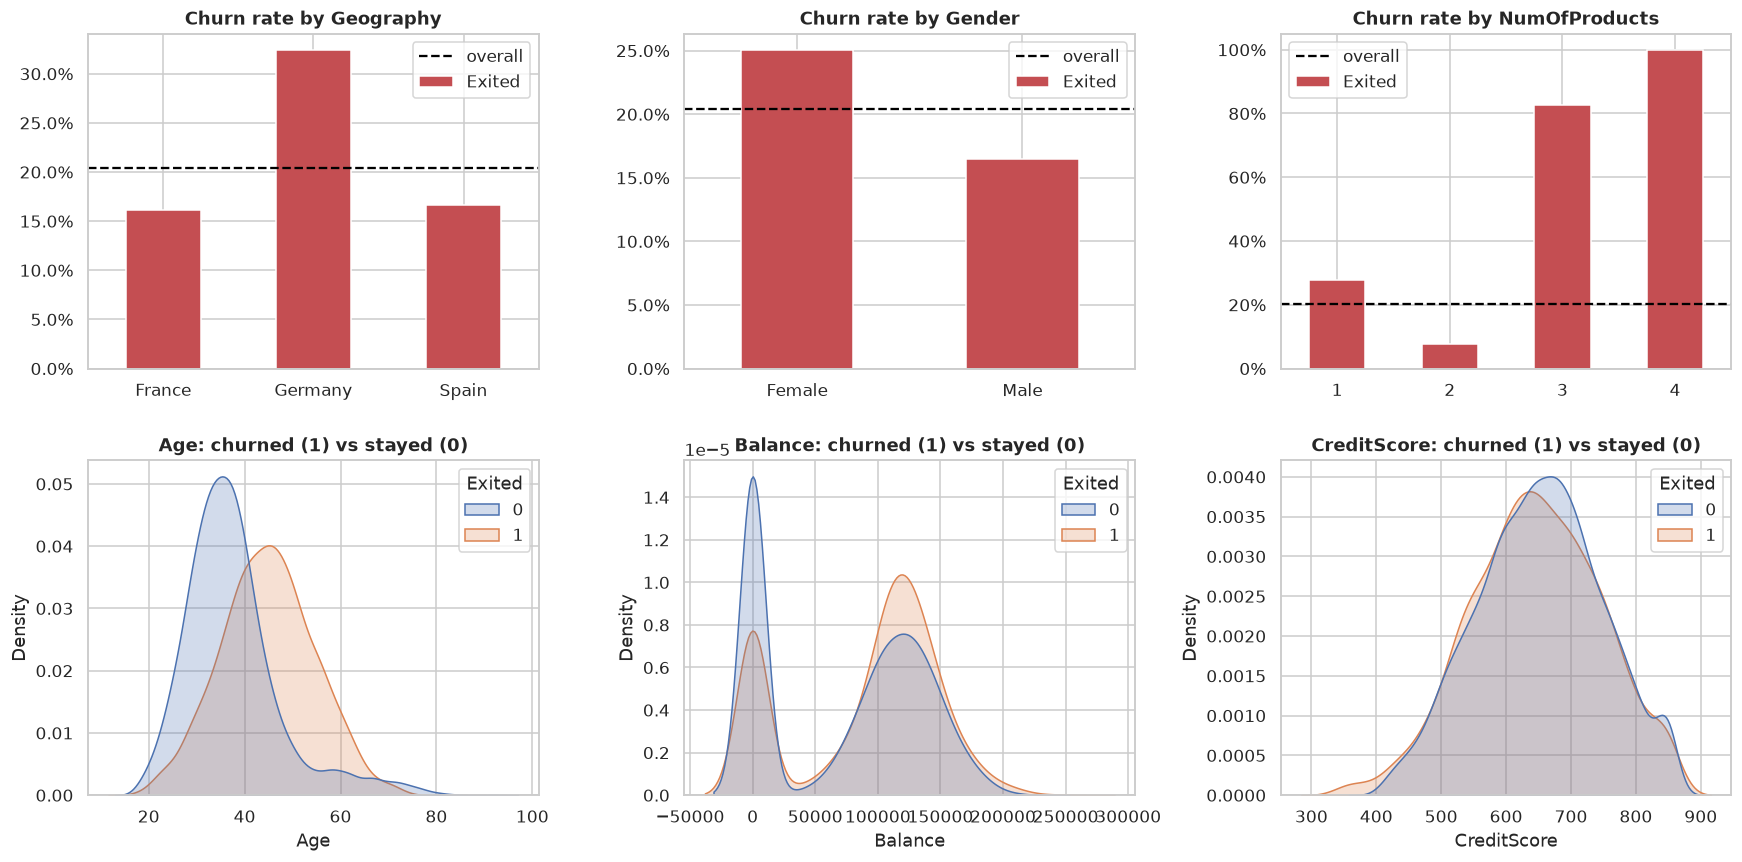

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes[0], ["Geography", "Gender", "NumOfProducts"]):
    raw.groupby(col)["Exited"].mean().plot.bar(ax=ax, color="#c44e52")
    ax.axhline(churn_rate, ls="--", c="black", label="overall"); ax.set_title(f"Churn rate by {col}")
    ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=0); ax.legend()
for ax, col in zip(axes[1], ["Age", "Balance", "CreditScore"]):
    sns.kdeplot(data=raw, x=col, hue="Exited", common_norm=False, fill=True, ax=ax); ax.set_title(f"{col}: churned (1) vs stayed (0)")
plt.tight_layout(); plt.show()

**What the charts suggest (before any model):**
- **Age** is a strong signal: churners are noticeably older on average.
- **Germany** churns about twice as much as France or Spain.
- **Number of products** has a U-shape: 2 products is the "sweet spot", while 3 to 4 products churn heavily (a small group).
- **Inactive members** (`IsActiveMember = 0`) churn more (check below).

The model will check whether these patterns hold once everything is considered *together*.

In [5]:
raw.groupby("IsActiveMember")["Exited"].agg(["mean", "size"]).rename(columns={"mean": "churn_rate", "size": "customers"}).style.format({"churn_rate": "{:.1%}"})

,churn_rate,customers
IsActiveMember,,
0,26.9%,4849
1,14.3%,5151


## 2. Features and preprocessing pipeline
Models only understand numbers. The steps are:
- **Feature engineering**: create helpful new columns from existing ones.
- **One-hot encoding**: turn text categories (Geography, Gender) into 0/1 columns.
- **Scaling** (logistic regression only): put numeric columns on a similar scale. Tree models like XGBoost don't need it.

Everything goes into a scikit-learn **Pipeline**, so the exact same steps run on training data and on new data. This prevents "leakage" mistakes.

### 🧑‍💻 YOUR TURN #2: create and pick the features
**Task A, create one feature:** inside `make_features`, uncomment the `ProductsPerYear` line (remove the `# `) or write your own idea.

**Task B, pick the features list:** `NUM_FEATURES` is the list the model is allowed to use. Choose your own:
- remove a feature you think is useless (e.g. `"HasCrCard"`) and see whether AUC changes,
- remove `"Age"` to see how much the model depends on it,
- add your new feature's name to the list.

Then **Run All** and write down the XGBoost CV AUC in section 4. The defaults work, so you can leave everything as it is the first time.

In [6]:
def make_features(df):
    d = df.copy()
    d["BalanceZero"] = (d["Balance"] == 0).astype(int)                  # many customers have exactly 0 balance
    d["BalanceToSalary"] = d["Balance"] / (d["EstimatedSalary"] + 1)    # how much of their income sits in the bank
    d["AgeOver50"] = (d["Age"] >= 50).astype(int)
    d["InactiveSenior"] = ((d["IsActiveMember"] == 0) & (d["Age"] >= 50)).astype(int)
    # HINT (Task A): uncomment the next line, then add "ProductsPerYear" to NUM_FEATURES below
    # d["ProductsPerYear"] = d["NumOfProducts"] / (d["Tenure"] + 1)
    return d

CAT_FEATURES = ["Geography", "Gender"]
NUM_FEATURES = ["CreditScore", "Age", "Tenure", "Balance", "NumOfProducts", "HasCrCard", "IsActiveMember",
                "EstimatedSalary", "BalanceZero", "BalanceToSalary", "AgeOver50", "InactiveSenior"]
# HINT (Task B): delete or add names in this list. Any name that isn't a column is skipped automatically.
TARGET = "Exited"

data = make_features(raw)
skipped = [c for c in NUM_FEATURES if c not in data.columns]
NUM_FEATURES = [c for c in NUM_FEATURES if c in data.columns]
if skipped: print("Skipped (not a column, check spelling or uncomment it in make_features):", skipped)
print(f"{len(CAT_FEATURES)} categorical + {len(NUM_FEATURES)} numeric features: {NUM_FEATURES}")

2 categorical + 12 numeric features: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'BalanceZero', 'BalanceToSalary', 'AgeOver50', 'InactiveSenior']


### Train/test split
**20% of customers are held back as a test set** that no model sees until the very end. It's our honest estimate of how the model would do on new customers. `stratify` keeps the churn rate the same (~20%) in both parts.

In [7]:
X = data[CAT_FEATURES + NUM_FEATURES]
y = data[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"train: {len(X_train):,} customers ({y_train.mean():.1%} churn) | test: {len(X_test):,} customers ({y_test.mean():.1%} churn)")

def make_preprocessor(scale_numeric):
    return ColumnTransformer([
        ("cat", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), CAT_FEATURES),
        ("num", StandardScaler() if scale_numeric else "passthrough", NUM_FEATURES),
    ], verbose_feature_names_out=False)

train: 8,000 customers (20.4% churn) | test: 2,000 customers (20.3% churn)


## 3. Baseline: logistic regression
Always start simple. Logistic regression draws a weighted line through the features and outputs a probability of churn. If a fancy model can't beat it, the fancy model isn't worth it.

**The two main metrics:**
- **ROC-AUC**: if you pick a random churner and a random stayer, how often does the model give the churner a higher risk score? 0.5 = coin flip, 1.0 = perfect.
- **PR-AUC (average precision)**: how *precise* the model stays as it tries to find more churners. Random guessing scores about the churn rate (~0.20), so anything well above 0.20 is real signal.

Logistic regression  ROC-AUC 0.776 | PR-AUC 0.530


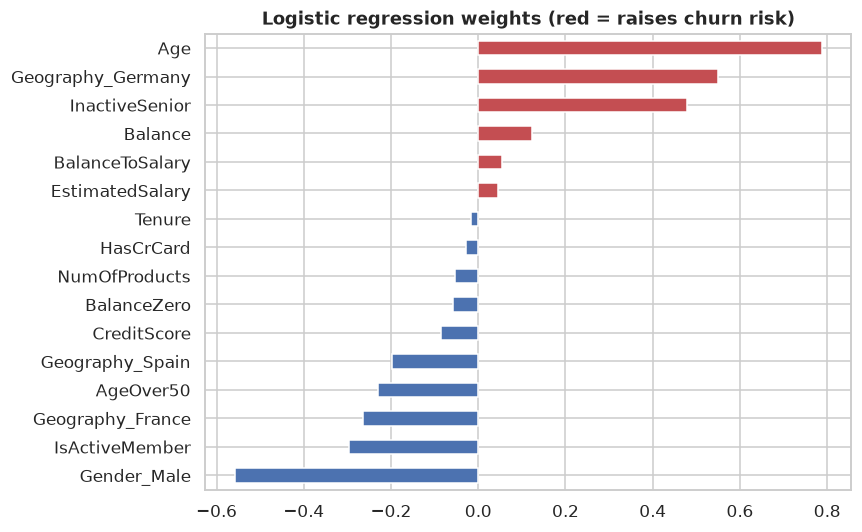

In [8]:
logreg = Pipeline([("pre", make_preprocessor(scale_numeric=True)),
                   ("model", LogisticRegression(max_iter=2000, class_weight="balanced"))])
logreg.fit(X_train, y_train)
p_lr = logreg.predict_proba(X_test)[:, 1]
print(f"Logistic regression  ROC-AUC {roc_auc_score(y_test, p_lr):.3f} | PR-AUC {average_precision_score(y_test, p_lr):.3f}")

coefs = pd.Series(logreg.named_steps["model"].coef_[0], index=logreg.named_steps["pre"].get_feature_names_out()).sort_values()
fig, ax = plt.subplots(figsize=(8, 5))
coefs.plot.barh(ax=ax, color=np.where(coefs > 0, "#c44e52", "#4c72b0"))
ax.set_title("Logistic regression weights (red = raises churn risk)"); plt.tight_layout(); plt.show()

## 4. XGBoost with stratified cross-validation and early stopping
**XGBoost** builds hundreds of small decision trees, where each new tree fixes the mistakes of the previous ones. It handles non-linear patterns (like the U-shape in NumOfProducts) that a straight line can't.

Two safety tools:
- **Stratified 5-fold cross-validation (CV):** split the *training* data into 5 parts, train on 4 and validate on the 5th, rotating 5 times. That gives 5 scores instead of 1, so we can see how stable the model is.
- **Early stopping:** keep adding trees only while the validation score improves. Stop after 50 rounds with no gain. This prevents **overfitting** (memorising the training data).

We also keep each customer's **out-of-fold (OOF)** prediction, made by a model that never saw that customer. Later we use these to choose the profit threshold without touching the test set.

### 🧑‍💻 YOUR TURN #3: run a hyperparameter experiment
**Task:** change **one** setting, re-run this cell and the next one, and compare the CV AUC with the default (4, 0.05).
- `max_depth`: how deep each tree can grow. Try **2** (simpler) or **6** (more complex).
- `learning_rate`: try **0.1** (faster, rougher) or **0.02** (slower, smoother).

The cell after the training loop keeps a small **experiment log**, so every run you make is listed, like a lab notebook.
**Rule of thumb:** a change is only "better" if the gain is bigger than the ± spread.

In [9]:
# HINT: change ONE number at a time, e.g. max_depth=2 or max_depth=6, then re-run this cell and the next
XGB_PARAMS = dict(
    max_depth=4,          # <- try 2 or 6
    learning_rate=0.05,   # <- try 0.02 or 0.1
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=3,
    reg_lambda=1.0,
)

pre_tree = make_preprocessor(scale_numeric=False).fit(X_train)
feat_names = list(pre_tree.get_feature_names_out())
Xtr = pd.DataFrame(pre_tree.transform(X_train), columns=feat_names, index=X_train.index).astype(float)
Xte = pd.DataFrame(pre_tree.transform(X_test), columns=feat_names, index=X_test.index).astype(float)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
oof = np.zeros(len(Xtr)); fold_auc, best_iters = [], []
for k, (tr_idx, va_idx) in enumerate(skf.split(Xtr, y_train), 1):
    m = xgb.XGBClassifier(n_estimators=3000, eval_metric="auc", early_stopping_rounds=50,
                          random_state=SEED, n_jobs=-1, **XGB_PARAMS)
    m.fit(Xtr.iloc[tr_idx], y_train.iloc[tr_idx], eval_set=[(Xtr.iloc[va_idx], y_train.iloc[va_idx])], verbose=False)
    oof[va_idx] = m.predict_proba(Xtr.iloc[va_idx])[:, 1]
    fold_auc.append(roc_auc_score(y_train.iloc[va_idx], oof[va_idx])); best_iters.append(m.best_iteration + 1)
    print(f"fold {k}: AUC {fold_auc[-1]:.3f}  (stopped at {best_iters[-1]} trees)")
print(f"\nCV ROC-AUC: {np.mean(fold_auc):.3f} ± {np.std(fold_auc):.3f} | OOF PR-AUC: {average_precision_score(y_train, oof):.3f}")

# Final model: train on ALL training data with the average number of trees found by early stopping
n_trees = int(np.mean(best_iters))
xgb_model = xgb.XGBClassifier(n_estimators=n_trees, random_state=SEED, n_jobs=-1, **XGB_PARAMS).fit(Xtr, y_train)
p_xgb = xgb_model.predict_proba(Xte)[:, 1]
print(f"Final model uses {n_trees} trees")

# Experiment log: each run of this cell adds a row
if "experiment_log" not in globals():
    experiment_log = []
experiment_log.append({"max_depth": XGB_PARAMS["max_depth"], "learning_rate": XGB_PARAMS["learning_rate"],
                       "n_features": len(feat_names), "trees": n_trees,
                       "cv_auc": round(np.mean(fold_auc), 4), "cv_auc_std": round(np.std(fold_auc), 4)})
display(pd.DataFrame(experiment_log))

fold 1: AUC 0.867  (stopped at 150 trees)
fold 2: AUC 0.874  (stopped at 103 trees)
fold 3: AUC 0.877  (stopped at 248 trees)


fold 4: AUC 0.848  (stopped at 63 trees)
fold 5: AUC 0.862  (stopped at 148 trees)

CV ROC-AUC: 0.866 ± 0.010 | OOF PR-AUC: 0.698
Final model uses 142 trees


,max_depth,learning_rate,n_features,trees,cv_auc,cv_auc_std
0,4,0.05,16,142,0.8656,0.01


## 5. Metrics on the untouched test set
- **ROC-AUC / PR-AUC**: explained above.
- **Recall at top 10%:** if the retention team can only call the 10% riskiest customers, what share of all churners do they reach? Random calling reaches about 10%.
- **Calibration:** when the model says "30% risk", do about 30% of those customers really churn? This matters because the profit maths uses the probabilities directly.

In [10]:
def recall_at_top(y_true, p, frac=0.10):
    n = int(len(p) * frac); idx = np.argsort(-p)[:n]
    return np.asarray(y_true)[idx].sum() / np.asarray(y_true).sum()

def precision_at_top(y_true, p, frac=0.10):
    n = int(len(p) * frac); idx = np.argsort(-p)[:n]
    return np.asarray(y_true)[idx].mean()

results = pd.DataFrame({
    name: {"ROC-AUC": roc_auc_score(y_test, p), "PR-AUC": average_precision_score(y_test, p),
           "Recall @ top 10%": recall_at_top(y_test, p), "Precision @ top 10%": precision_at_top(y_test, p),
           "Brier score (lower = better)": brier_score_loss(y_test, p)}
    for name, p in {"Random guess": np.random.default_rng(SEED).random(len(y_test)), "Logistic regression": p_lr, "XGBoost": p_xgb}.items()
}).T
results.style.format("{:.3f}").highlight_max(subset=["ROC-AUC", "PR-AUC", "Recall @ top 10%"], color="#c7e9c0")

,ROC-AUC,PR-AUC,Recall @ top 10%,Precision @ top 10%,Brier score (lower = better)
Random guess,0.515,0.224,0.128,0.260,0.331
Logistic regression,0.776,0.530,0.297,0.605,0.187
XGBoost,0.871,0.722,0.420,0.855,0.099


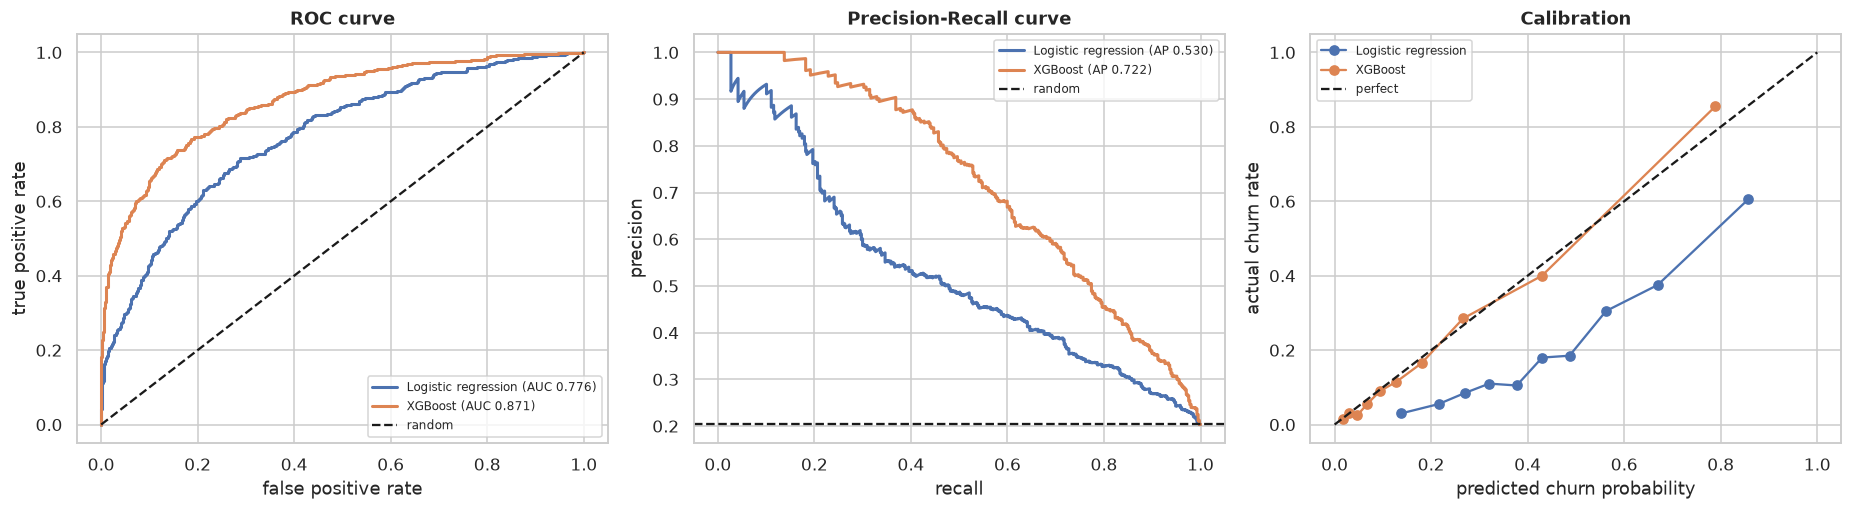

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for name, p in {"Logistic regression": p_lr, "XGBoost": p_xgb}.items():
    fpr, tpr, _ = roc_curve(y_test, p); axes[0].plot(fpr, tpr, lw=2, label=f"{name} (AUC {roc_auc_score(y_test, p):.3f})")
    pr, rc, _ = precision_recall_curve(y_test, p); axes[1].plot(rc, pr, lw=2, label=f"{name} (AP {average_precision_score(y_test, p):.3f})")
    fy, fx = calibration_curve(y_test, p, n_bins=10, strategy="quantile"); axes[2].plot(fx, fy, marker="o", label=name)
axes[0].plot([0, 1], [0, 1], "k--", label="random"); axes[0].set(title="ROC curve", xlabel="false positive rate", ylabel="true positive rate")
axes[1].axhline(y_test.mean(), ls="--", c="k", label="random"); axes[1].set(title="Precision-Recall curve", xlabel="recall", ylabel="precision")
axes[2].plot([0, 1], [0, 1], "k--", label="perfect"); axes[2].set(title="Calibration", xlabel="predicted churn probability", ylabel="actual churn rate")
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.show()

**How to read this honestly:**
- XGBoost should rank customers clearly better than logistic regression. On this dataset, most published models land around **0.85 to 0.87 ROC-AUC**, so don't expect 0.95+. If you ever see that, suspect leakage.
- The logistic regression used `class_weight="balanced"`, which pushes its probabilities **upwards** (it is deliberately over-predicting churn). You can see that in its calibration curve. XGBoost wasn't re-weighted, so its probabilities sit close to the diagonal, which is what we need for the profit maths.

## 6. SHAP: *why* does the model think a customer will churn?
XGBoost is powerful but hard to read. **SHAP values** split each prediction into contributions from each feature: "+0.8 because Age = 58, −0.3 because IsActiveMember = 1…". Added together (plus a baseline), they give the model's output (in log-odds).

- **Global view** (beeswarm): each dot is one customer. Red = high feature value, blue = low. Dots to the right push toward churn.
- **Local view** (waterfall): the explanation for one specific customer, the kind of story a retention agent could use.

XGBoost computes exact tree SHAP values itself (`pred_contribs=True`). The `shap` library is only used to draw the charts, with a plain matplotlib fallback.

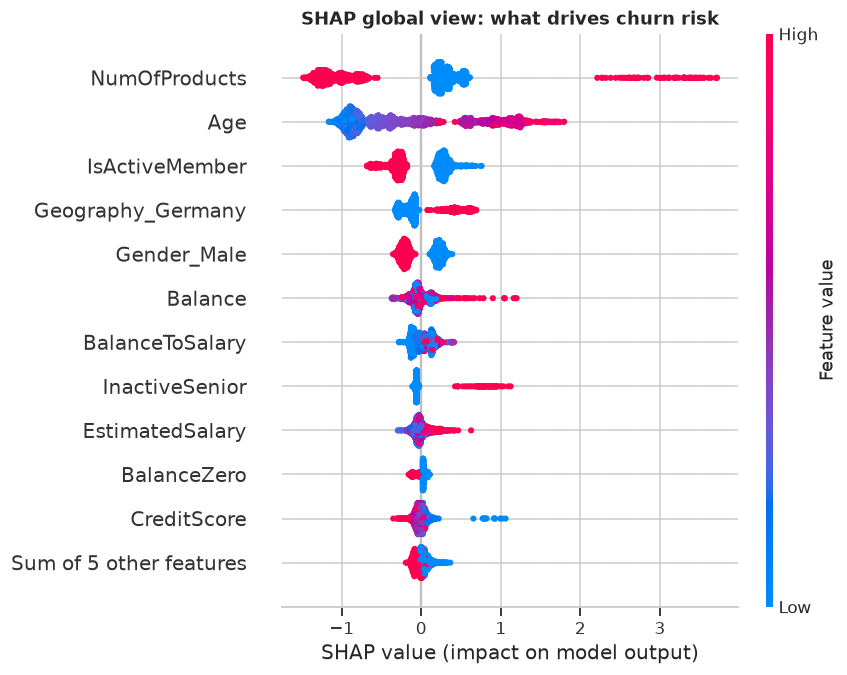

Top 5 drivers: NumOfProducts, Age, IsActiveMember, Geography_Germany, Gender_Male


In [12]:
dtest = xgb.DMatrix(Xte, feature_names=feat_names)
contribs = xgb_model.get_booster().predict(dtest, pred_contribs=True)
shap_values, base_value = contribs[:, :-1], contribs[0, -1]

try:
    import shap
    explanation = shap.Explanation(values=shap_values, base_values=np.full(len(Xte), base_value), data=Xte.values, feature_names=feat_names)
    HAVE_SHAP = True
except Exception as e:
    print("shap plotting not available, using matplotlib fallback:", e); HAVE_SHAP = False

mean_abs = pd.Series(np.abs(shap_values).mean(axis=0), index=feat_names).sort_values()
if HAVE_SHAP:
    shap.plots.beeswarm(explanation, max_display=12, show=False); plt.title("SHAP global view: what drives churn risk"); plt.tight_layout(); plt.show()
else:
    mean_abs.tail(12).plot.barh(figsize=(8, 5), title="Mean |SHAP|: what drives churn risk"); plt.tight_layout(); plt.show()
print("Top 5 drivers:", ", ".join(mean_abs.sort_values(ascending=False).index[:5]))

### 🧑‍💻 YOUR TURN #4: explain one customer in plain English
**Task:** change `CUSTOMER_RANK` (0 = the riskiest test customer, 500 = middle risk, 1999 = the safest), run the cell, and fill in `MY_EXPLANATION` with one sentence a retention agent could say, based on the biggest bars.

Customer at risk rank 0: predicted churn probability 98.8% | actually churned: True


,Geography,Gender,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,BalanceZero,BalanceToSalary,AgeOver50,InactiveSenior
5950,Germany,Female,834,57,8,112281.6,3,1,0,140225.14,0,0.800718,1,1


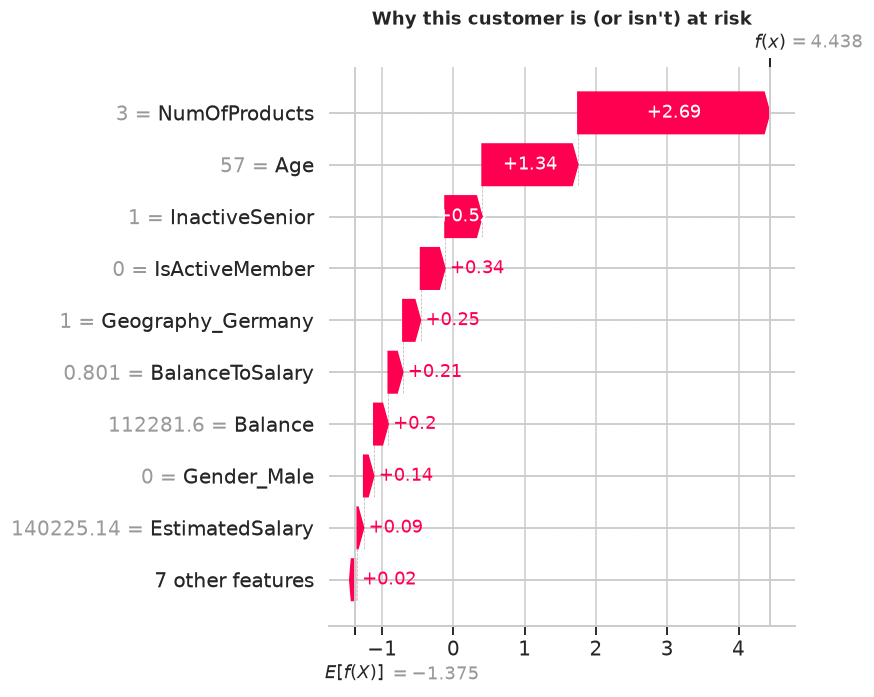

Your explanation: e.g. Older, inactive customer with 3+ products in Germany: call them first.


In [13]:
CUSTOMER_RANK = 0   # <- try 1, 50, 500, 1999

# HINT: read the 2-3 longest bars in the waterfall chart. Red pushes toward churn, blue toward staying.
MY_EXPLANATION = "e.g. Older, inactive customer with 3+ products in Germany: call them first."   # <- write your own

order = np.argsort(-p_xgb)
i = order[min(CUSTOMER_RANK, len(order) - 1)]
print(f"Customer at risk rank {CUSTOMER_RANK}: predicted churn probability {p_xgb[i]:.1%} | actually churned: {bool(y_test.iloc[i])}")
display(X_test.iloc[[i]])
if HAVE_SHAP:
    shap.plots.waterfall(explanation[i], max_display=10, show=False); plt.title("Why this customer is (or isn't) at risk"); plt.tight_layout(); plt.show()
else:
    s = pd.Series(shap_values[i], index=feat_names); s = s.reindex(s.abs().sort_values().index).tail(10)
    s.plot.barh(color=np.where(s > 0, "#c44e52", "#4c72b0"), figsize=(8, 5), title="Why this customer is (or isn't) at risk"); plt.tight_layout(); plt.show()
print("Your explanation:", MY_EXPLANATION)

## 7. Profit-based targeting: who should get a retention offer?
A churn probability alone doesn't tell us what to do. Money does. For each customer:

$$\text{Expected value of an offer} = P(\text{churn}) \times \text{customer value} \times \text{offer success rate} - \text{offer cost}$$

- **P(churn)**: from the model
- **Customer value**: profit we keep if the customer stays. The dataset has no profit column, so we **assume** a simple formula (edit it below).
- **Offer success rate**: share of would-be churners the offer actually saves
- **Offer cost**: paid for *every* customer we contact, churner or not

We then choose the **probability threshold** (contact everyone above it) that maximises profit. The threshold is chosen on the **out-of-fold training predictions** and only then checked on the test set, so the test result stays honest.

### 🧑‍💻 YOUR TURN #5: be the retention manager
**Task:** set the business numbers yourself, re-run from here to the end, and answer: *how many customers should we contact, and how much do we make vs contacting everyone?*
- `OFFER_COST`: a $50 fee waiver? $10 for an email-only offer? $150 for a personal call plus a gift?
- `SUCCESS_RATE`: 0.30 means the offer saves 30% of the churners who get it
- `customer_value()`: what a retained customer is worth. Try the flat version in the hint.

**What to notice:** cheap offers mean you contact more people; expensive offers mean you only contact the riskiest. If the offer is expensive enough, even "contact everyone" loses money.

Average assumed customer value: $930 | offer cost $50 | success rate 30%


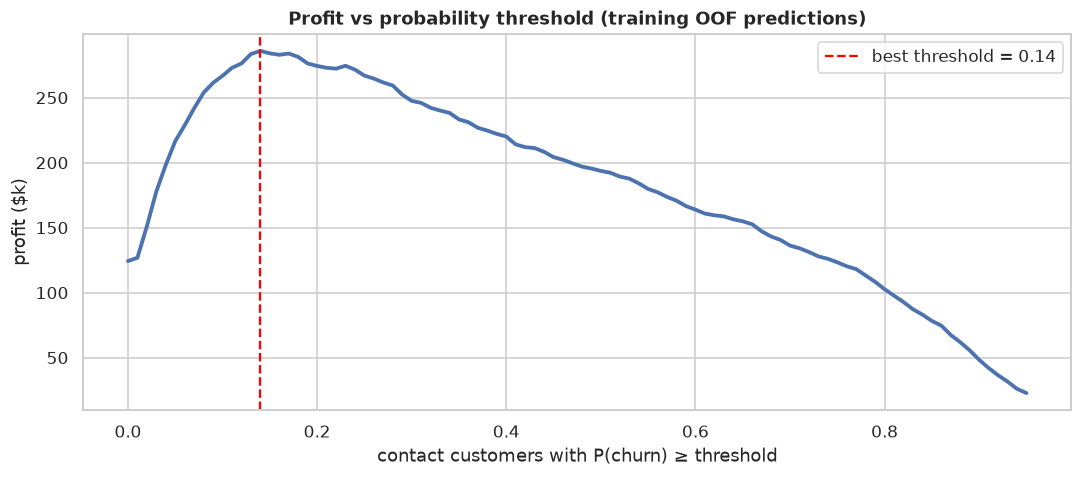

In [14]:
OFFER_COST = 50.0       # <- try 10 or 150 ($ per customer contacted)
SUCCESS_RATE = 0.30     # <- try 0.15 or 0.50 (share of contacted churners who are saved)

def customer_value(df):
    """Assumed annual profit from keeping a customer: base + 1% margin on balance + $40 per product."""
    # HINT: for a flat $500 per customer, replace the line below with:  return pd.Series(500.0, index=df.index)
    return 100 + 0.01 * df["Balance"] + 40 * df["NumOfProducts"]

val_train, val_test = customer_value(X_train).values, customer_value(X_test).values
print(f"Average assumed customer value: ${val_test.mean():,.0f} | offer cost ${OFFER_COST:.0f} | success rate {SUCCESS_RATE:.0%}")

def campaign_profit(y_true, contact, value):
    """Realised profit of contacting `contact` customers: saved value from real churners minus all offer costs."""
    y_true = np.asarray(y_true)
    return float((y_true * value * SUCCESS_RATE * contact).sum() - OFFER_COST * contact.sum())

# Choose the threshold on OOF predictions (training data only)
thresholds = np.linspace(0.0, 0.95, 96)
profit_oof = [campaign_profit(y_train, oof >= t, val_train) for t in thresholds]
best_t = thresholds[int(np.argmax(profit_oof))]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(thresholds, np.array(profit_oof) / 1e3, lw=2.5)
ax.axvline(best_t, ls="--", c="red", label=f"best threshold = {best_t:.2f}")
ax.set(title="Profit vs probability threshold (training OOF predictions)", xlabel="contact customers with P(churn) ≥ threshold", ylabel="profit ($k)")
ax.legend(); plt.tight_layout(); plt.show()

### Test-set check: compare targeting strategies
- **Contact nobody**: $0, the baseline
- **Contact everyone**: the blanket campaign
- **Top 10% by risk**: a fixed-capacity rule
- **Model + best threshold**: the threshold chosen above
- **Expected value > 0**: contact a customer only if *their own* expected value is positive (uses each customer's value, not just their risk)
- **Perfect foresight**: contact only true churners (an upper bound we can't reach)

,customers contacted,churners reached,profit ($),vs contact everyone ($)
Contact nobody,0,0,$0,"$-29,703"
Contact everyone,"2,000",407,"$29,703",$+0
Top 10% by risk,200,171,"$46,427","$+16,724"
Model: P(churn) ≥ 0.14,839,346,"$69,528","$+39,825"
Expected value > 0,715,271,"$75,871","$+46,168"
Perfect foresight (upper bound),407,407,"$109,353","$+79,650"


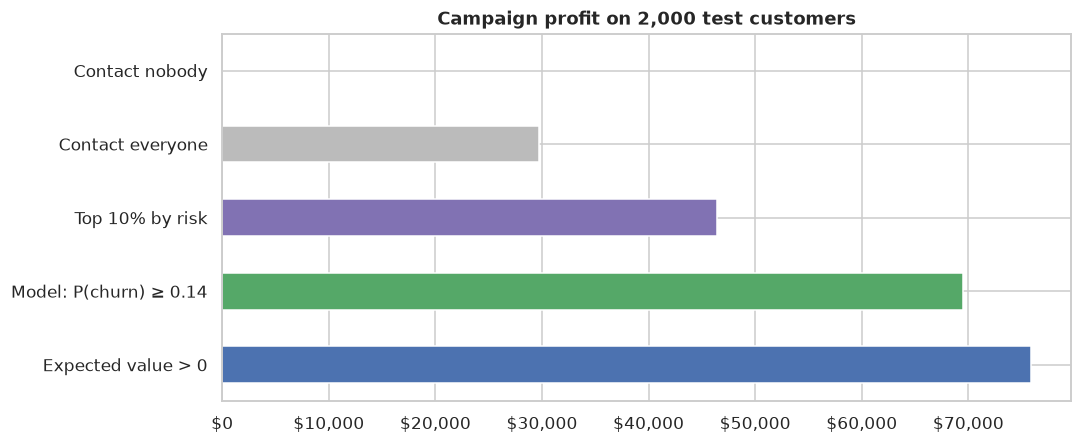

In [15]:
ev_test = p_xgb * val_test * SUCCESS_RATE - OFFER_COST
top10 = np.zeros(len(p_xgb), bool); top10[np.argsort(-p_xgb)[: int(0.1 * len(p_xgb))]] = True
strategies = {
    "Contact nobody": np.zeros(len(y_test), bool),
    "Contact everyone": np.ones(len(y_test), bool),
    "Top 10% by risk": top10,
    f"Model: P(churn) ≥ {best_t:.2f}": p_xgb >= best_t,
    "Expected value > 0": ev_test > 0,
    "Perfect foresight (upper bound)": y_test.values == 1,
}
tbl = pd.DataFrame({k: {"customers contacted": int(c.sum()), "churners reached": int(y_test.values[c].sum()),
                        "profit ($)": campaign_profit(y_test, c, val_test)} for k, c in strategies.items()}).T
everyone = tbl.loc["Contact everyone", "profit ($)"]
tbl["vs contact everyone ($)"] = tbl["profit ($)"] - everyone
display(tbl.style.format({"customers contacted": "{:,.0f}", "churners reached": "{:,.0f}", "profit ($)": "${:,.0f}", "vs contact everyone ($)": "${:+,.0f}"}))

fig, ax = plt.subplots(figsize=(10, 4.2))
tbl["profit ($)"].iloc[:-1].plot.barh(ax=ax, color=["#bbbbbb", "#bbbbbb", "#8172b3", "#55a868", "#4c72b0"])
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}")); ax.set_title(f"Campaign profit on {len(y_test):,} test customers"); ax.invert_yaxis()
plt.tight_layout(); plt.show()

## 8. Conclusions

In [16]:
best_strategy = tbl.drop(["Perfect foresight (upper bound)"])["profit ($)"].idxmax()
bp = tbl.loc[best_strategy]
print(f"1. XGBoost test ROC-AUC {results.loc['XGBoost','ROC-AUC']:.3f} vs logistic regression {results.loc['Logistic regression','ROC-AUC']:.3f} (CV {np.mean(fold_auc):.3f} ± {np.std(fold_auc):.3f}).")
print(f"   PR-AUC {results.loc['XGBoost','PR-AUC']:.3f} vs a random baseline of about {y_test.mean():.2f}.")
print(f"2. Calling the riskiest 10% reaches {results.loc['XGBoost','Recall @ top 10%']:.0%} of all churners (random calling: ~10%).")
print(f"3. Top churn drivers (SHAP): {', '.join(mean_abs.sort_values(ascending=False).index[:4])}.")
print(f"4. With ${OFFER_COST:.0f} offers and a {SUCCESS_RATE:.0%} success rate, contacting everyone earns ${everyone:,.0f}.")
print(f"   The best strategy ('{best_strategy}') earns ${bp['profit ($)']:,.0f} by contacting {int(bp['customers contacted']):,} of {len(y_test):,} customers,")
print(f"   ${bp['profit ($)'] - everyone:+,.0f} vs contacting everyone, and {bp['profit ($)'] / tbl.loc['Perfect foresight (upper bound)', 'profit ($)']:.0%} of the perfect-foresight maximum.")

1. XGBoost test ROC-AUC 0.871 vs logistic regression 0.776 (CV 0.866 ± 0.010).
   PR-AUC 0.722 vs a random baseline of about 0.20.
2. Calling the riskiest 10% reaches 42% of all churners (random calling: ~10%).
3. Top churn drivers (SHAP): NumOfProducts, Age, IsActiveMember, Geography_Germany.
4. With $50 offers and a 30% success rate, contacting everyone earns $29,703.
   The best strategy ('Expected value > 0') earns $75,871 by contacting 715 of 2,000 customers,
   $+46,168 vs contacting everyone, and 69% of the perfect-foresight maximum.


**What to take away**
- **Accuracy is the wrong goal.** The right question is "who is worth contacting?", and the answer depends on offer cost, success rate and customer value as much as on the model.
- **The model's job is ranking.** An AUC around 0.86 is a solid, realistic result on this data. Not perfect: many churners still look like stayers.
- **Explainability helps adoption.** SHAP shows the main drivers (number of products, age, activity, being in Germany), so the retention team can understand *why* someone is flagged.

**Honest limitations**
- Customer value, offer cost and success rate are **assumptions**. In real life you'd estimate the success rate with an **A/B test** (offer vs. no offer) and use real margin data.
- The data is a single snapshot with no dates, so we can't check how the model holds up over time.
- Profit on 2,000 test customers is noisy. Treat the uplift as a direction to test, not a guaranteed figure.

**Ideas to go further:** tune with Optuna, try LightGBM/CatBoost, model *uplift* (who changes behaviour because of the offer), or add a capacity limit (e.g. the team can only make 150 calls a week).

*This notebook is a learning project. If it helped you, an upvote is appreciated, and feedback in the comments is very welcome.*

---
**Shahzad Raza** · E-commerce & marketing data analyst · [GitHub](https://github.com/Shahzrazaa) · [LinkedIn](https://www.linkedin.com/in/shahzadrazaa/)

📋 Free Amazon listing health checklist: https://adsmithai.gumroad.com/l/rxzumn

More notebooks: https://www.kaggle.com/shahzadrazaa/code